# Blocking probabilities of ter sites in the oriZ mutant

VeloGP models delays at genomic features deterministically: a replisome passing a feature is slowed down by the
factor $g$. Alternatively, a feature could block replisomes *permanently* with some probability $p$, and let them
pass without delay otherwise. The `p_block` column of the vx feature table (`VelocityModel.g_range_block_probability()`)
converts a fitted deterministic delay into the blocking probability that reproduces the abundance just past the
feature, using the time at which the next replisome from the opposite direction would arrive.

This notebook checks how well that works. It simulates abundances from the blocking (mixture) model, fits the
deterministic VeloGP model to them, and compares `p_block` to the true blocking probabilities.

**Geometry and parameters.** E. coli MG1655 oriZ mutant, which replicates from two origins, oriC (3.926 Mb) and oriZ
(345 kb). The relevant ter sites are terC (1.609 Mb) and terB (1.684 Mb). Both block forks moving clockwise, i.e. the
fork moving rightwards from oriZ towards oriC, which reaches terC first and then terB. The simulation uses the
parameters of the VeloGP fit of sample `T37_DNA_RCe504_R1_Exp_S2` (LB, 2023; `m1`, $v(t)$ timescale 0.2): growth
rate, $v(t)$, origin delays, and $g$ of all rRNA genes and ter sites, as well as the window positions and (relative)
standard errors of the data.

**Mixture model.** The clockwise fork from oriZ is stalled forever at terC with probability $p_C$. If it passes terC,
it is stalled at terB with probability $p_B$ (i.e. $p_B$ is conditional on passing terC). The true probabilities are
the `p_block` values implied by the real fit. Everything else is deterministic and follows the usual model with the
fitted parameters, with $g = 1$ at terC and terB. A stalled fork leaves the rest of the segment between oriZ and oriC
to the counter-clockwise fork from oriC.

**Fitting.** The fit is initialized with the true parameters of the deterministic part of the model ($g = 1$ at terC
and terB), and then uses deterministic L-BFGS optimization of all parameters, i.e. $v_0$, $h(t)$, $g(x)$ and the
origin delays (as in the last two phases of `FitVelocityModel.optimize_parameters()`, which however keep the delays
fixed), not the stochastic search. The settings ($v(t)$ covariance, timescale and magnitude, delay scale) are those of
the real fit.

**Stages.** Complexity increases step by step:
1. terC only, constant $v(t) = v_0$, no other delays
2. terC only, fitted $v(t)$
3. terC, fitted $v(t)$, fitted delays at all rRNA genes and the other ter sites
4. terC and terB, fitted $v(t)$, other fitted delays

In [1]:
import math, os, sys, time
import numpy as np
import pandas as pd
import torch as pt
from torch import nn
from matplotlib import pyplot as pp

# Import VeloGP from the repository
sys.path.insert(0, os.path.abspath(".."))
from velogp import model, fit
from velogp.model import dtensor

pt.set_num_threads(os.cpu_count())

## Fitted parameters of the real sample

The values below were extracted from the VeloGP fit of sample `T37_DNA_RCe504_R1_Exp_S2` (LB 2023, settings `m1`,
$v(t)$ timescale 0.2, files `T37_DNA_RCe504_R1_Exp_S2.velogp.m1-0.2.{log,vt,vx,abd}.gz` in the EcoliEctopicOrigins
project) and are hard-coded here, so that the notebook only depends on the VeloGP repository.

* The growth rate is that of the sample in `data/meta/LB_2023/growthrates.tab` of that project.
* $v(t)$ is given on the grid on which $h(t)$ is defined. The grid is the one the CLI constructs from the growth rate.
* oriC fires at time 0, the firing delay of oriZ was read off its replisome trajectory.
* The data windows are the 1 kb windows of the real sample, except those removed by filtering (low mappability etc.).
* Standard errors are generated with the error model fitted to the real data, $s^2 = q^2 + d y^2$, where $d$ is the
  fitted overdispersion and $q^2 = a y$ is the Poisson part. $a$ was estimated from the real data as
  $q^2 = s^2 - d y^2$; the per-window variation of $q$ (mappability etc.) is ignored. Abundances are scaled to the mean
  of the real data before applying the error model.

In [2]:
# Settings of the real fit
GROWTHRATE = 1.527                      # 1/h, from data/meta/LB_2023/growthrates.tab
DT = 3600 * math.log(2) / GROWTHRATE    # doubling time [s]
VT_COVARIANCE, VT_TIMESCALE, VT_MAGNITUDE, VT_TMAX, VT_RESOLUTION = "m1", 0.2, 0.25, 3, 100
DELAYSCALE = 0.01

# E. coli MG1655 (U00096.3), origins as used by the VeloGP CLI (midpoints of the origins in data/origins.bed)
L = 4_641_652
ORIGINS = [("oriZ", 345_166), ("oriC", 3_925_859)]
ORI_Z, ORI_C = ORIGINS[0][1], ORIGINS[1][1]

# Fitted parameters
V0_FIT = 695.74795                      # bp/s, v(t) = v0 * h(t)
DELAYS = {"oriZ": 45.673, "oriC": 0.0}  # origin firing delays [s]
REPLICATIONTIME_FIT = 2879.10           # duration of the replication cycle [s], used as a check below
# Fitted g of all features (rRNA genes and ter sites): (name, begin, end, g)
FEATURES = [
    ("rna-b0201", 223770, 225312, 11.5687),
    ("rna-b0204", 225758, 228662, 7.72008),
    ("rna-b0205", 228755, 228875, 183.468),
    ("terH", 599670, 599693, 12.4646),
    ("terI", 625410, 625433, 2104.7),
    ("terE", 1082204, 1082227, 1),
    ("terD", 1279526, 1279549, 1),
    ("terA", 1341744, 1341767, 1843.27),
    ("terC", 1609156, 1609179, 20182.1),
    ("terB", 1684225, 1684248, 15782.1),
    ("terF", 2317663, 2317686, 1),
    ("terG", 2377355, 2377378, 1),
    ("terJ", 2576244, 2576267, 1),
    ("rna-b2588", 2726068, 2726188, 1),
    ("rna-b2589", 2726280, 2729184, 1),
    ("rna-b2591", 2729615, 2731157, 1),
    ("rna-b3272", 3423422, 3423542, 56.2533),
    ("rna-b3274", 3423667, 3423787, 126.786),
    ("rna-b3275", 3423879, 3426783, 6.80785),
    ("rna-b3278", 3427220, 3428762, 3.41954),
    ("rna-b3756", 3941807, 3943349, 3.00608),
    ("rna-b3758", 3943703, 3946607, 2.01551),
    ("rna-b3759", 3946699, 3946819, 34.8901),
    ("rna-b3851", 4035530, 4037072, 1),
    ("rna-b3854", 4037518, 4040423, 1),
    ("rna-b3855", 4040516, 4040636, 1),
    ("rna-b3968", 4166658, 4168200, 1),
    ("rna-b3970", 4168640, 4171544, 1),
    ("rna-b3971", 4171636, 4171756, 1),
    ("rna-b4007", 4208146, 4209688, 1),
    ("rna-b4009", 4210042, 4212946, 1),
    ("rna-b4010", 4213039, 4213159, 1),
]

# Data windows: midpoints of all 1 kb windows, except runs (first, last) of windows removed by filtering
EXCLUDED_WINDOWS = [
    (15499, 17499), (19499, 20499), (223499, 229499), (257499, 258499), (270499, 275499),
    (278499, 280499), (290499, 291499), (314499, 316499), (380499, 382499), (391499, 393499),
    (525499, 527499), (566499, 568499), (574499, 578499), (580499, 581499), (607499, 609499),
    (687499, 689499), (729499, 735499), (781499, 782499), (1049499, 1050499), (1093499, 1097499),
    (1268499, 1270499), (1299499, 1300499), (1395499, 1397499), (1423499, 1423499), (1427499, 1428499),
    (1431499, 1434499), (1467499, 1470499), (1528499, 1529499), (1531499, 1533499), (1551499, 1552499),
    (1570499, 1572499), (1632499, 1636499), (1650499, 1651499), (1978499, 1979499), (2065499, 2070499),
    (2101499, 2103499), (2169499, 2171499), (2288499, 2290499), (2304499, 2305499), (2513499, 2515499),
    (2521499, 2521499), (2725499, 2731499), (2759499, 2760499), (2996499, 2997499), (3129499, 3131499),
    (3185499, 3187499), (3365499, 3367499), (3423499, 3429499), (3469499, 3471499), (3583499, 3584499),
    (3618499, 3622499), (3624499, 3625499), (3651499, 3653499), (3665499, 3667499), (3761499, 3766499),
    (3941499, 3947499), (4034499, 4041499), (4166499, 4172499), (4175499, 4177499), (4207499, 4213499),
    (4295499, 4296499), (4497499, 4499499), (4507499, 4508499), (4641499, 4641499),
]
X_DATA = np.arange(1499, L, 1000)
for first, last in EXCLUDED_WINDOWS:
    X_DATA = X_DATA[(X_DATA < first) | (X_DATA > last)]
# Error model s^2 = ERR_A * y + ERR_D * y^2 for abundances y on the scale of the real data (mean Y_MEAN)
ERR_D = 2.353e-4                        # fitted overdispersion d
ERR_A = 2.810e-4                        # Poisson part q^2 = ERR_A * y
Y_MEAN = 0.944

In [3]:
# Fitted v(t) on the grid H_TGRID on which h(t) is defined (as constructed by the CLI)
H_TGRID = np.arange(0, DT * VT_TMAX, DT * VT_TIMESCALE / VT_RESOLUTION)
VT_FIT = np.array([
    544.413, 542.184, 539.914, 537.603, 535.278, 532.991, 530.781, 528.624, 526.442, 524.171,
    521.820, 519.472, 517.206, 515.033, 512.905, 510.777, 508.648, 506.541, 504.454, 502.362,
    500.256, 498.159, 496.106, 494.097, 492.100, 490.086, 488.061, 486.058, 484.103, 482.206,
    480.373, 478.621, 476.966, 475.402, 473.904, 472.445, 471.015, 469.626, 468.300, 467.062,
    465.928, 464.895, 463.930, 462.984, 462.023, 461.058, 460.130, 459.280, 458.508, 457.783,
    457.069, 456.360, 455.682, 455.076, 454.574, 454.188, 453.903, 453.699, 453.562, 453.508,
    453.569, 453.783, 454.161, 454.675, 455.275, 455.920, 456.603, 457.359, 458.232, 459.235,
    460.335, 461.478, 462.643, 463.865, 465.199, 466.665, 468.222, 469.796, 471.342, 472.870,
    474.422, 476.038, 477.738, 479.530, 481.423, 483.420, 485.507, 487.659, 489.852, 492.069,
    494.300, 496.535, 498.774, 501.027, 503.315, 505.659, 508.078, 510.589, 513.205, 515.920,
    518.708, 521.558, 524.502, 527.608, 530.917, 534.382, 537.889, 541.330, 544.678, 547.976,
    551.262, 554.516, 557.693, 560.781, 563.842, 566.959, 570.175, 573.460, 576.756, 580.031,
    583.302, 586.602, 589.952, 593.351, 596.788, 600.254, 603.740, 607.223, 610.668, 614.056,
    617.408, 620.784, 624.239, 627.788, 631.401, 635.026, 638.622, 642.158, 645.615, 648.988,
    652.310, 655.646, 659.049, 662.519, 666.014, 669.508, 673.041, 676.679, 680.440, 684.256,
    688.033, 691.738, 695.435, 699.208, 703.080, 707.001, 710.917, 714.826, 718.772, 722.790,
    726.867, 730.971, 735.093, 739.247, 743.433, 747.603, 751.674, 755.572, 759.280, 762.849,
    766.365, 769.898, 773.461, 777.011, 780.483, 783.851, 787.157, 790.481, 793.888, 797.371,
    800.859, 804.258, 807.507, 810.596, 813.557, 816.431, 819.249, 822.021, 824.727, 827.327,
    829.777, 832.071, 834.250, 836.380, 838.498, 840.583, 842.588, 844.509, 846.409, 848.368,
    850.403, 852.448, 854.436, 856.370, 858.320, 860.327, 862.349, 864.306, 866.177, 868.016,
    869.882, 871.763, 873.599, 875.375, 877.140, 878.923, 880.650, 882.192, 883.499, 884.660,
    885.823, 887.046, 888.270, 889.422, 890.516, 891.625, 892.767, 893.860, 894.803, 895.562,
    896.171, 896.659, 897.003, 897.178, 897.211, 897.153, 897.010, 896.726, 896.262, 895.670,
    895.073, 894.551, 894.078, 893.574, 893.012, 892.468, 892.058, 891.832, 891.732, 891.657,
    891.549, 891.440, 891.403, 891.469, 891.589, 891.680, 891.701, 891.698, 891.763, 891.946,
    892.229, 892.560, 892.914, 893.299, 893.722, 894.162, 894.591, 895.015, 895.466, 895.961,
    896.481, 897.002, 897.532, 898.109, 898.774, 899.563, 900.528, 901.722, 903.149, 904.726,
    906.338, 907.940, 909.589, 911.361, 913.249, 915.173, 917.105, 919.132, 921.375, 923.849,
    926.433, 929.002, 931.553, 934.198, 937.040, 940.091, 943.294, 946.582, 949.876, 953.067,
    956.062, 958.878, 961.659, 964.557, 967.583, 970.608, 973.513, 976.311, 979.120, 982.034,
    985.039, 988.059, 991.031, 993.928, 996.743, 999.493, 1002.236, 1005.040, 1007.918, 1010.810,
    1013.643, 1016.410, 1019.148, 1021.856, 1024.476, 1026.983, 1029.464, 1032.051, 1034.756, 1037.424,
    1039.871, 1042.054, 1044.083, 1046.073, 1048.041, 1049.960, 1051.875, 1053.880, 1055.996, 1058.113,
    1060.100, 1061.943, 1063.739, 1065.550, 1067.321, 1068.960, 1070.470, 1071.951, 1073.477, 1075.031,
    1076.558, 1078.055, 1079.551, 1081.026, 1082.390, 1083.592, 1084.692, 1085.798, 1086.936, 1088.018,
    1088.967, 1089.818, 1090.661, 1091.519, 1092.311, 1092.968, 1093.522, 1094.060, 1094.608, 1095.104,
    1095.512, 1095.891, 1096.318, 1096.768, 1097.097, 1097.180, 1097.029, 1096.739, 1096.355, 1095.819,
    1095.058, 1094.090, 1092.994, 1091.818, 1090.534, 1089.115, 1087.609, 1086.112, 1084.672, 1083.246,
    1081.747, 1080.127, 1078.401, 1076.618, 1074.829, 1073.081, 1071.400, 1069.775, 1068.155, 1066.496,
    1064.802, 1063.105, 1061.384, 1059.538, 1057.441, 1055.039, 1052.377, 1049.528, 1046.514, 1043.315,
    1039.932, 1036.419, 1032.827, 1029.118, 1025.157, 1020.802, 1016.021, 1010.918, 1005.644, 1000.288,
    994.830, 989.203, 983.374, 977.378, 971.262, 965.021, 958.588, 951.910, 945.017, 938.005,
    930.962, 923.892, 916.743, 909.473, 902.096, 894.651, 887.135, 879.506, 871.740, 863.884,
    856.038, 848.274, 840.579, 832.873, 825.073, 817.153, 809.146, 801.105, 793.066, 785.032,
    777.000, 768.984, 761.026, 753.175, 745.451, 737.827, 730.251, 722.690, 715.164, 707.725,
    700.428, 693.298, 686.330, 679.492, 672.741, 666.029, 659.330, 652.661, 646.072, 639.611,
    633.285, 627.066, 620.921, 614.857, 608.911, 603.116, 597.477, 591.978, 586.616, 581.417,
    576.409, 571.600, 566.959, 562.449, 558.053, 553.795, 549.707, 545.803, 542.064, 538.455,
    534.952, 531.553, 528.260, 525.062, 521.937, 518.878, 515.908, 513.068, 510.390, 507.876,
    505.499, 503.225, 501.040, 498.955, 497.002, 495.214, 493.604, 492.159, 490.853, 489.662,
    488.588, 487.649, 486.869, 486.266, 485.850, 485.627, 485.587, 485.700, 485.923, 486.225,
    486.607, 487.095, 487.723, 488.517, 489.495, 490.674, 492.063, 493.647, 495.394, 497.273,
    499.265, 501.363, 503.554, 505.823, 508.168, 510.609, 513.169, 515.848, 518.617, 521.455,
    524.379, 527.445, 530.704, 534.156, 537.754, 541.441, 545.188, 548.997, 552.879, 556.825,
    560.812, 564.822, 568.869, 572.993, 577.234, 581.592, 586.026, 590.486, 594.946, 599.410,
    603.888, 608.378, 612.872, 617.372, 621.891, 626.428, 630.960, 635.452, 639.870, 644.180,
    648.325, 652.239, 655.893, 659.334, 662.651, 665.907, 669.106, 672.229, 675.296, 678.357,
    681.434, 684.480, 687.415, 690.201, 692.853, 695.384, 697.756, 699.911, 701.840, 703.606,
    705.285, 706.897, 708.412, 709.801, 711.058, 712.185, 713.163, 713.977, 714.652, 715.239,
    715.763, 716.193, 716.501, 716.717, 716.932, 717.201, 717.474, 717.609, 717.474, 717.032,
    716.357, 715.580, 714.818, 714.127, 713.471, 712.751, 711.879, 710.855, 709.765, 708.694,
    707.639, 706.513, 705.237, 703.826, 702.371, 700.955, 699.593, 698.249, 696.898, 695.547,
    694.212, 692.890, 691.563, 690.220, 688.870, 687.528, 686.205, 684.901, 683.615, 682.353,
    681.141, 680.021, 679.024, 678.146, 677.334, 676.537, 675.759, 675.061, 674.494, 674.035,
    673.599, 673.115, 672.585, 672.058, 671.559, 671.076, 670.608, 670.215, 669.993, 669.990,
    670.171, 670.461, 670.825, 671.279, 671.840, 672.487, 673.181, 673.931, 674.798, 675.850,
    677.087, 678.441, 679.836, 681.251, 682.728, 684.335, 686.102, 688.005, 689.971, 691.928,
    693.833, 695.699, 697.576, 699.531, 701.618, 703.877, 706.319, 708.931, 711.673, 714.501,
    717.404, 720.414, 723.588, 726.968, 730.549, 734.294, 738.168, 742.162, 746.283, 750.528,
    754.861, 759.223, 763.579, 767.950, 772.416, 777.049, 781.852, 786.749, 791.657, 796.580,
    801.622, 806.902, 812.434, 818.104, 823.754, 829.309, 834.815, 840.369, 846.025, 851.762,
    857.536, 863.349, 869.254, 875.309, 881.515, 887.816, 894.150, 900.515, 906.973, 913.597,
    920.404, 927.333, 934.303, 941.276, 948.265, 955.294, 962.365, 969.488, 976.717, 984.136,
    991.772, 999.559, 1007.394, 1015.249, 1023.201, 1031.328, 1039.591, 1047.846, 1055.978, 1063.994,
    1071.977, 1079.953, 1087.851, 1095.608, 1103.267, 1110.947, 1118.701, 1126.448, 1134.057, 1141.504,
    1148.893, 1156.337, 1163.817, 1171.200, 1178.371, 1185.340, 1192.211, 1199.056, 1205.841, 1212.463,
    1218.847, 1224.988, 1230.928, 1236.688, 1242.240, 1247.528, 1252.497, 1257.122, 1261.410, 1265.392,
    1269.108, 1272.587, 1275.817, 1278.734, 1281.237, 1283.241, 1284.709, 1285.655, 1286.097, 1286.021,
    1285.398, 1284.233, 1282.575, 1280.489, 1277.996, 1275.056, 1271.609, 1267.625, 1263.107, 1258.082,
    1252.578, 1246.636, 1240.306, 1233.635, 1226.661, 1219.427, 1211.997, 1204.440, 1196.776, 1188.958,
    1180.911, 1172.596, 1164.032, 1155.261, 1146.299, 1137.132, 1127.747, 1118.154, 1108.371, 1098.419,
    1088.328, 1078.158, 1067.977, 1057.814, 1047.641, 1037.407, 1027.079, 1016.665, 1006.199, 995.724,
    985.291, 974.944, 964.694, 954.514, 944.392, 934.376, 924.561, 915.010, 905.686, 896.485,
    887.346, 878.301, 869.432, 860.772, 852.288, 843.948, 835.797, 827.930, 820.410, 813.203,
    806.217, 799.389, 792.729, 786.289, 780.095, 774.113, 768.278, 762.542, 756.909, 751.425,
    746.145, 741.099, 736.287, 731.687, 727.278, 723.033, 718.916, 714.900, 710.989, 707.232,
    703.681, 700.353, 697.231, 694.304, 691.588, 689.101, 686.801, 684.598, 682.428, 680.314,
    678.332, 676.504, 674.756, 672.987, 671.173, 669.381, 667.681, 666.067, 664.499, 662.985,
    661.613, 660.463, 659.524, 658.697, 657.885, 657.067, 656.280, 655.561, 654.922, 654.359,
    653.862, 653.412, 652.983, 652.567, 652.192, 651.888, 651.639, 651.396, 651.135, 650.899,
    650.754, 650.712, 650.716, 650.705, 650.687, 650.717, 650.811, 650.911, 650.951, 650.926,
    650.898, 650.920, 650.989, 651.083, 651.216, 651.435, 651.761, 652.161, 652.592, 653.053,
    653.588, 654.218, 654.905, 655.581, 656.212, 656.824, 657.463, 658.150, 658.870, 659.597,
    660.303, 660.956, 661.529, 662.018, 662.446, 662.845, 663.220, 663.542, 663.777, 663.920,
    663.994, 664.038, 664.091, 664.189, 664.357, 664.594, 664.863, 665.109, 665.294, 665.428,
    665.565, 665.753, 666.002, 666.263, 666.474, 666.599, 666.664, 666.720, 666.801, 666.888,
    666.943, 666.956, 666.964, 667.008, 667.094, 667.183, 667.241, 667.275, 667.330, 667.449,
    667.644, 667.902, 668.215, 668.581, 668.993, 669.434, 669.872, 670.270, 670.602, 670.868,
    671.095, 671.321, 671.556, 671.764, 671.902, 671.971, 672.026, 672.119, 672.243, 672.340,
    672.372, 672.357, 672.335, 672.300, 672.205, 672.027, 671.809, 671.616, 671.456, 671.269,
    671.006, 670.686, 670.367, 670.055, 669.690, 669.217, 668.661, 668.112, 667.630, 667.190,
    666.721, 666.197, 665.659, 665.162, 664.722, 664.314, 663.920, 663.556, 663.256, 663.030,
    662.839, 662.614, 662.296, 661.886, 661.462, 661.134, 660.957, 660.888, 660.828, 660.729,
    660.636, 660.622, 660.688, 660.738, 660.675, 660.493, 660.277, 660.113, 660.011, 659.926,
    659.812, 659.653, 659.449, 659.216, 659.010, 658.926, 659.034, 659.313, 659.665, 660.004,
    660.328, 660.693, 661.130, 661.606, 662.071, 662.519, 662.989, 663.506, 664.054, 664.598,
    665.123, 665.640, 666.160, 666.683, 667.205, 667.723, 668.228, 668.698, 669.114, 669.473,
    669.782, 670.035, 670.227, 670.372, 670.515, 670.681, 670.834, 670.903, 670.860, 670.759,
    670.681, 670.647, 670.602, 670.493, 670.345, 670.226, 670.166, 670.117, 670.015, 669.861,
    669.718, 669.640, 669.617, 669.598, 669.549, 669.468, 669.369, 669.271, 669.201, 669.204,
    669.306, 669.488, 669.692, 669.865, 669.986, 670.050, 670.045, 669.959, 669.796, 669.576,
    669.310, 668.990, 668.618, 668.233, 667.886, 667.594, 667.337, 667.096, 666.894, 666.763,
    666.694, 666.631, 666.541, 666.462, 666.465, 666.569, 666.707, 666.804, 666.864, 666.966,
    667.178, 667.486, 667.814, 668.106, 668.358, 668.598, 668.853, 669.141, 669.485, 669.887,
    670.307, 670.675, 670.946, 671.146, 671.343, 671.589, 671.884, 672.208, 672.559, 672.948,
    673.357, 673.733, 674.028, 674.256, 674.482, 674.762, 675.091, 675.413, 675.683, 675.909,
    676.140, 676.406, 676.684, 676.925, 677.105, 677.250, 677.411, 677.603, 677.800, 677.968,
    678.123, 678.326, 678.621, 678.982, 679.338, 679.643, 679.924, 680.239, 680.596, 680.929,
    681.158, 681.265, 681.304, 681.353, 681.451, 681.594, 681.763, 681.948, 682.148, 682.374,
    682.651, 683.012, 683.468, 683.980, 684.489, 684.968, 685.444, 685.973, 686.594, 687.312,
    688.127, 689.040, 690.030, 691.031, 691.953, 692.755, 693.471, 694.180, 694.930, 695.710,
    696.475, 697.189, 697.839, 698.418, 698.919, 699.339, 699.681, 699.946, 700.127, 700.210,
    700.204, 700.138, 700.049, 699.965, 699.896, 699.844, 699.792, 699.718, 699.614, 699.508,
    699.461, 699.515, 699.653, 699.797, 699.873, 699.867, 699.823, 699.795, 699.796, 699.805,
    699.794, 699.769, 699.774, 699.861, 700.059, 700.359, 700.718, 701.097, 701.482, 701.880,
    702.287, 702.680, 703.044, 703.403, 703.824, 704.348, 704.934, 705.476, 705.894, 706.212,
    706.536, 706.957, 707.460, 707.951, 708.338, 708.609, 708.825, 709.056, 709.326, 709.607,
    709.853, 710.033, 710.143, 710.204, 710.245, 710.286, 710.331, 710.371, 710.398, 710.414,
    710.437, 710.486, 710.555, 710.611, 710.599, 710.486, 710.284, 710.052, 709.852, 709.710,
    709.606, 709.511, 709.416, 709.336, 709.286, 709.260, 709.234, 709.187, 709.105, 708.990,
    708.857, 708.738, 708.665, 708.649, 708.668, 708.677, 708.637, 708.529, 708.341, 708.071,
    707.731, 707.351, 706.954, 706.520, 705.991, 705.329, 704.572, 703.807, 703.097, 702.427,
    701.735, 700.989, 700.206, 699.424, 698.653, 697.891, 697.156, 696.483, 695.880, 695.304,
    694.702, 694.084, 693.519, 693.067, 692.713, 692.390, 692.058, 691.740, 691.485, 691.299,
    691.136, 690.944, 690.705, 690.435, 690.157, 689.895, 689.690, 689.592, 689.624, 689.749,
    689.890, 689.974, 689.975, 689.921, 689.870, 689.884, 689.995, 690.174, 690.344, 690.434,
    690.448, 690.481, 690.658, 691.041, 691.603, 692.269, 692.984, 693.742, 694.556, 695.433,
    696.366, 697.344, 698.358, 699.383, 700.375, 701.277, 702.050, 702.690, 703.234, 703.740,
    704.255, 704.782, 705.282, 705.705, 706.036, 706.305, 706.550, 706.779, 706.969, 707.104,
    707.201, 707.291, 707.381, 707.448, 707.461, 707.414, 707.329, 707.229, 707.127, 707.026,
    706.926, 706.826, 706.715, 706.581, 706.421, 706.245, 706.058, 705.861, 705.652, 705.437,
    705.227, 705.024, 704.822, 704.621, 704.438, 704.291, 704.176, 704.072, 703.963, 703.863,
    703.819, 703.880, 704.067, 704.360, 704.702, 705.027, 705.298, 705.533, 705.786, 706.095,
    706.437, 706.755, 707.020, 707.275, 707.600, 708.033, 708.536, 709.030, 709.469, 709.861,
    710.238, 710.621, 711.013, 711.415, 711.819, 712.197, 712.513, 712.758, 712.964, 713.166,
    713.363, 713.516, 713.610, 713.676, 713.768, 713.890, 713.985, 713.990, 713.907, 713.807,
    713.774, 713.853, 714.047, 714.341, 714.720, 715.155, 715.604, 716.026, 716.393, 716.692,
    716.913, 717.052, 717.120, 717.139, 717.122, 717.063, 716.945, 716.770, 716.558, 716.329,
    716.087, 715.832, 715.578, 715.360, 715.210, 715.129, 715.099, 715.098, 715.108, 715.121,
])
assert len(VT_FIT) == len(H_TGRID)

print(f"growth rate {GROWTHRATE}/h (doubling time {DT / 60:.1f} min), v0 = {V0_FIT:.0f} bp/s, "
      f"v(t) between {VT_FIT.min():.0f} and {VT_FIT.max():.0f} bp/s")
print("origin delays:", ", ".join(f"{n} {d:.1f}s" for n, d in DELAYS.items()))
print(f"{len(X_DATA)} data windows")

growth rate 1.527/h (doubling time 27.2 min), v0 = 696 bp/s, v(t) between 454 and 1286 bp/s
origin delays: oriZ 45.7s, oriC 0.0s
4422 data windows


## Model

`make_model()` builds a model with the given features and sets its parameters. `real_fit_model()` reproduces the
model fitted to the real sample; its `p_block` values for terC and terB are used as the true blocking probabilities.

In [4]:
def make_model(features, vt, delays):
    # features: list of (name, begin, end, g); vt: v(t) on H_TGRID; delays: origin name -> delay
    m = model.VelocityModel(
        model.TemporalModel(h_tgrid=dtensor(H_TGRID), v0_min=dtensor(10.0), v0_max=dtensor(10000.0)),
        [model.ChromosomeModel("U00096.3", L, True, origins=pt.tensor([o for _, o in ORIGINS], dtype=pt.int32),
                               origin_names=[n for n, _ in ORIGINS],
                               g_xranges_l=pt.tensor([f[1] for f in features], dtype=pt.int32),
                               g_xranges_u=pt.tensor([f[2] for f in features], dtype=pt.int32),
                               g_names=[f[0] for f in features],
                               g_strands=pt.zeros(len(features), dtype=pt.int32),
                               g_delayscale=dtensor([DELAYSCALE] * len(features)))])
    m.temporal.growthrate[0] = GROWTHRATE / 3600
    m.temporal.h_cov_function = VT_COVARIANCE
    m.temporal.h_sigma[0] = VT_MAGNITUDE
    m.temporal.h_timescale[0] = DT * VT_TIMESCALE
    with pt.no_grad():
        m.temporal.v0 = dtensor(V0_FIT)
        m.temporal.h_log_raw = pt.log(dtensor(vt / V0_FIT))
        m.chromosomes[0].g_delta = dtensor([f[3] - 1.0 for f in features])
        m.chromosomes[0].set_delay(m.temporal, dtensor([delays[n] for n, _ in ORIGINS]))
    return m

def real_fit_model():
    return make_model(FEATURES, VT_FIT, DELAYS)

m = real_fit_model()
with pt.no_grad():
    p_block_fit = m.g_range_block_probability().numpy()
    print(f"Replication time {m.completion_time().item():.2f}s (real fit: {REPLICATIONTIME_FIT:.2f}s)")
P_TRUE = {n: p_block_fit[i] for i, (n, *_) in enumerate(FEATURES) if n in ("terC", "terB")}
print("p_block of the real fit:", ", ".join(f"{n} {p:.3f}" for n, p in P_TRUE.items()))

Replication time 2879.10s (real fit: 2879.10s)
p_block of the real fit: terC 0.596, terB 0.991


In the real fit, the fork from oriZ exits terB only a few seconds before the fork from oriC arrives there, so the
two forks meet right behind terB. This makes $p_B$ close to 1.

## Stages, simulation and fitting

`simulate()` computes the virtual arrival times of the forks coming from the closest origin to the left and right of
each window with `ChromosomeModel.fork_arrival_times()`, sets the arrival times of the clockwise fork from oriZ beyond
the site at which it is stalled to $\infty$, and mixes the resulting abundances $e^{-\lambda t(x)}$ over the possible
outcomes. Noise is added according to the error model of the real data.

In [5]:
TER = {n: (n, l, u, P_TRUE[n]) for n, l, u, g in FEATURES if n in P_TRUE}
OTHER = [f for f in FEATURES if f[0] not in P_TRUE]

STAGES = {
    1: dict(ter=[TER["terC"]], other=False, vary=False),
    2: dict(ter=[TER["terC"]], other=False, vary=True),
    3: dict(ter=[TER["terC"]], other=True, vary=True),
    4: dict(ter=[TER["terC"], TER["terB"]], other=True, vary=True),
}

def stage_model(stage):
    # Model with the true parameters of the deterministic part of the model, g = 1 at the ter sites
    st = STAGES[stage]
    feats = [(n, l, u, 1.0) for n, l, u, _ in st["ter"]] + (OTHER if st["other"] else [])
    feats.sort(key=lambda f: f[1])
    vt = VT_FIT if st["vary"] else np.full_like(VT_FIT, V0_FIT)
    return make_model(feats, vt, DELAYS), feats

def simulate(stage):
    m, feats = stage_model(stage)
    c = m.chromosomes[0]
    x = dtensor(X_DATA)
    with pt.no_grad():
        u_fwd, u_rev = (u.numpy() for u in c.fork_arrival_times(c.prepare_input(x), m.temporal))
        lam = m.temporal.growthrate.item()
        # The clockwise fork from oriZ stops at the k-th ter site with probability prod_(j<k) (1 - p_j) * p_k
        outcomes, survive = [], 1.0
        for n, l, u, p in STAGES[stage]["ter"]:
            outcomes.append((survive * p, l))
            survive *= 1 - p
        outcomes.append((survive, ORI_C))
        y = np.zeros(len(X_DATA))
        for w, stop in outcomes:
            # Windows between the ter site at which the fork stops and oriC are not reached by the fork from oriZ
            blocked = (X_DATA >= stop) & (X_DATA < ORI_C)
            uu = np.minimum(np.where(blocked, np.inf, u_fwd), u_rev)
            y += w * np.exp(-lam * m.temporal.Hinv(dtensor(uu)).numpy())
    return y

def drops(stage, y):
    # Relative abundance drop between the windows just before and just after each ter site
    res = {}
    for n, l, u, p in STAGES[stage]["ter"]:
        i_after = np.searchsorted(X_DATA, u + 500)
        res[n] = 1 - y[i_after] / y[i_after - 2]
    return res

def fit_deterministic(stage, y_obs, s_obs):
    m, feats = stage_model(stage)
    c = m.chromosomes[0]
    m.temporal.h_switch_basis("eigenbasis_scaled")
    m.temporal.v0_log = nn.Parameter(m.temporal.v0_log)
    m.temporal.h_log_raw = nn.Parameter(m.temporal.h_log_raw)
    c.g_delta_scaled = nn.Parameter(c.g_delta_scaled)
    c.delay_scaled = nn.Parameter(c.delay_scaled)
    loss = model.VelocityModelLoss(x=dtensor(X_DATA), y_obs=dtensor(y_obs), s_obs=dtensor(s_obs), model=m,
                                   params=["temporal.v0_log", "chromosomes.0.delay_scaled", "temporal.h_log_raw",
                                           "chromosomes.0.g_delta_scaled"])
    alg = fit.FitVelocityModel(m, loss)
    params = [m.temporal.v0_log, c.delay_scaled, c.g_delta_scaled, m.temporal.h_log_raw]
    # As phases IV and V of FitVelocityModel.optimize_parameters(), but including the origin delays
    alg.run_lbfgs(params, lr_start=0.1, lr_end=1.0, iterations=1000, steps=10,
                  tolerance_change=-math.inf, line_search_fn="strong_wolfe")
    alg.run_lbfgs(params, lr_start=1.0, lr_end=1.0, iterations=100, steps=None, retry=30,
                  tolerance=1e-6, line_search_fn="strong_wolfe")
    return m, loss, feats

RESULTS = {}

def run_stage(stage, seed=1):
    y = simulate(stage)
    # Scale to the mean of the real data, generate standard errors with the error model and add noise
    y = y * Y_MEAN / y.mean()
    rng = np.random.default_rng(seed)
    s_obs = np.sqrt(ERR_A * y + ERR_D * y ** 2)
    y_obs = y + s_obs * rng.standard_normal(len(y))
    t0 = time.time()
    m, loss, feats = fit_deterministic(stage, y_obs, s_obs)
    elapsed = time.time() - t0
    with pt.no_grad():
        p_block = m.g_range_block_probability().numpy()
        forks = m.g_range_forks()
        g = m.chromosomes[0].g.numpy()
        y_pred = loss.y_pred().numpy()
        delays = m.chromosomes[0].delay(m.temporal).numpy()
    true_p = {n: p for n, _, _, p in STAGES[stage]["ter"]}
    true_g = {n: g_ for n, _, _, g_ in feats}
    rows = []
    for i, (n, l, u, _) in enumerate(feats):
        passing = (f"clockwise ({forks.origin_fwd[i]})" if forks.exit_fwd[i] <= forks.enter_rev[i] else
                   f"counter-clockwise ({forks.origin_rev[i]})" if forks.exit_rev[i] <= forks.enter_fwd[i] else
                   "both (meet inside)")
        rows.append(dict(stage=stage, feature=n, begin=l, end=u, g_true=true_g[n], g_fit=g[i], replicated_by=passing,
                         p_true=true_p.get(n, np.nan), p_block=p_block[i]))
    table = pd.DataFrame(rows)
    RESULTS[stage] = dict(y=y, y_obs=y_obs, y_pred=y_pred, model=m, table=table)
    print(f"Stage {stage}: fit took {elapsed:.0f}s, origin delays "
          + ", ".join(f"{n} {d:.1f}s (true {DELAYS[n]:.1f}s)" for (n, _), d in zip(ORIGINS, delays)))
    print("Abundance drops at ter sites:", ", ".join(f"{n} {100 * d:.1f}%" for n, d in drops(stage, y).items()))
    # Show the ter sites, and features whose fitted g deviates from the true g by more than 50%
    show = table.feature.isin(list(true_p)) | (np.abs(table.g_fit / table.g_true - 1) > 0.5)
    return table.loc[show]

def plot_stage(stage):
    r = RESULTS[stage]
    x, m = X_DATA, r["model"]
    fig, ax = pp.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(x / 1e6, r["y_obs"], ".", ms=1, color="grey", label="simulated data")
    ax[0].plot(x / 1e6, r["y_pred"], color="navy", lw=1, label="fit")
    for n, o in ORIGINS:
        ax[0].axvline(o / 1e6, color="green", lw=0.5)
        ax[0].text(o / 1e6, ax[0].get_ylim()[1], n, color="green", ha="left", va="top", fontsize=8)
    ax[0].set(xlabel="position [Mb]", ylabel="abundance", title="Whole genome")
    ax[0].legend(loc="lower left")
    sel = (x > 1.3e6) & (x < 2.6e6)
    ax[1].plot(x[sel] / 1e6, r["y"][sel], ".", ms=1.5, color="grey", label="simulated (noise-free)")
    ax[1].plot(x[sel] / 1e6, r["y_pred"][sel] / r["y_pred"].mean() * r["y"].mean(), color="navy", lw=1, label="fit")
    for k, (n, l, u, p) in enumerate(STAGES[stage]["ter"]):
        ax[1].axvline(l / 1e6, color="red", lw=0.5)
        ax[1].text(l / 1e6, ax[1].get_ylim()[1], n, color="red", ha="right" if k == 0 else "left", va="top",
                   fontsize=8)
    ax[1].set(xlabel="position [Mb]", title="Ter sites and meeting region")
    ax[1].legend(loc="lower right")
    with pt.no_grad():
        vt = m.temporal.v_t(m.temporal.h_tgrid).numpy()
        tc = m.completion_time().item()
    ax[2].plot(H_TGRID, VT_FIT if STAGES[stage]["vary"] else np.full_like(VT_FIT, V0_FIT), color="black", label="true")
    ax[2].plot(H_TGRID, vt, color="navy", label="fit")
    ax[2].axvline(tc, ls="--", lw=0.5, color="navy", label="fitted replication time")
    ax[2].set(xlabel="time [s]", ylabel="v(t) [bp/s]", xlim=(0, 1.2 * tc), title="Fork velocity")
    ax[2].legend()
    fig.suptitle(f"Stage {stage}")
    fig.tight_layout()
    pp.show()

## Stage 1: terC only, constant v(t), no other delays

In [6]:
run_stage(1)

Stage 1: fit took 70s, origin delays oriZ 44.5s (true 45.7s), oriC 0.0s (true 0.0s)
Abundance drops at ter sites: terC 27.7%


,stage,feature,begin,end,g_true,g_fit,replicated_by,p_true,p_block
0,1,terC,1609156,1609179,1.0,20182.095652,clockwise (oriZ),0.596052,0.752675


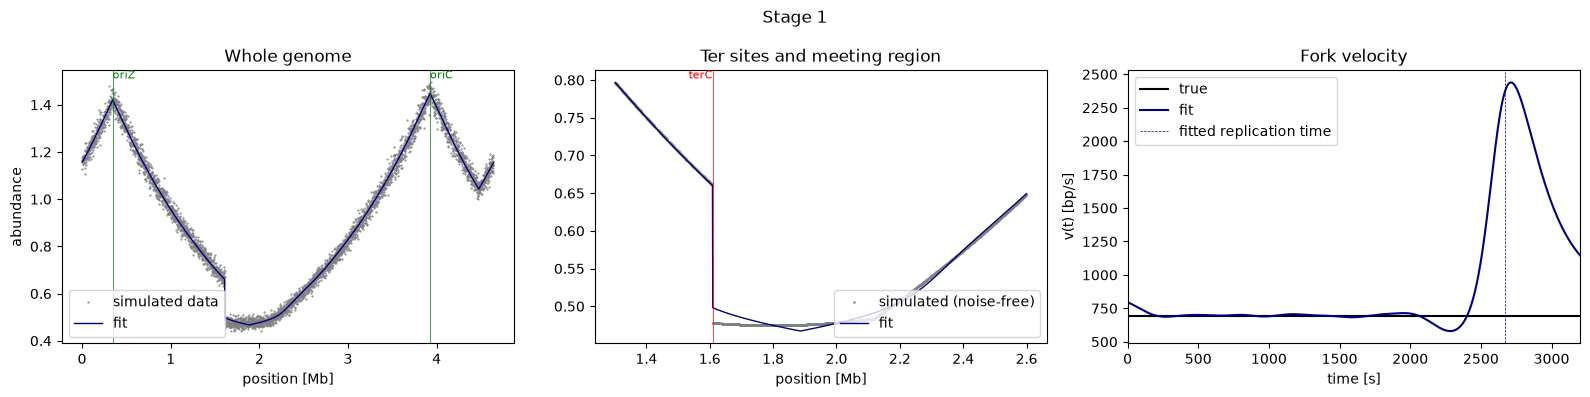

In [7]:
plot_stage(1)

## Stage 2: terC only, fitted v(t)

In [8]:
run_stage(2)

Stage 2: fit took 50s, origin delays oriZ 46.3s (true 45.7s), oriC 0.0s (true 0.0s)
Abundance drops at ter sites: terC 24.9%


,stage,feature,begin,end,g_true,g_fit,replicated_by,p_true,p_block
0,2,terC,1609156,1609179,1.0,17341.651972,clockwise (oriZ),0.596052,0.760113


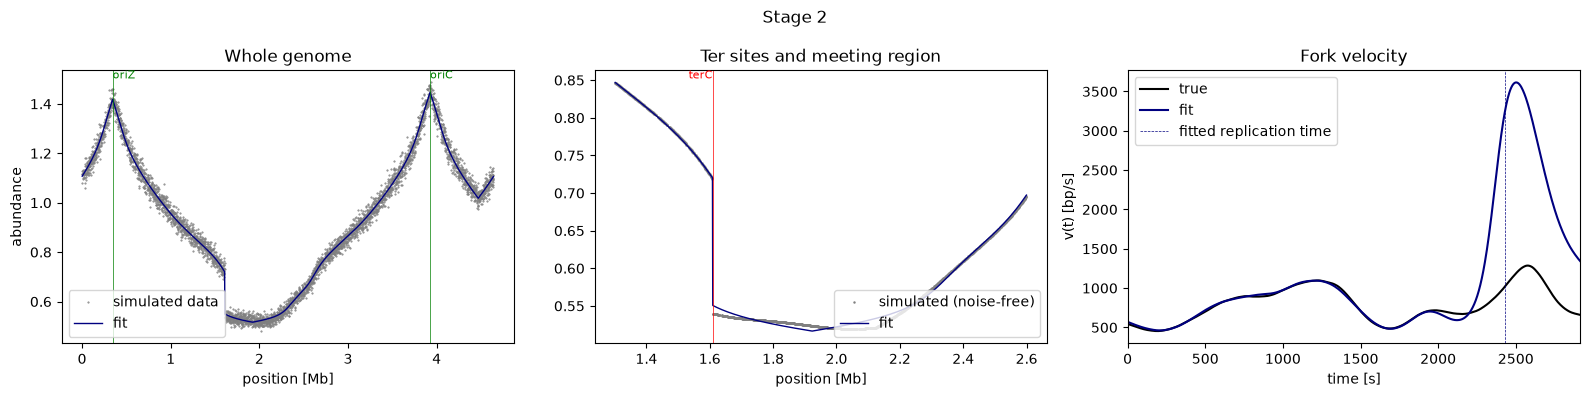

In [9]:
plot_stage(2)

## Stage 3: terC, fitted v(t), other fitted delays

The table lists the ter sites and all features whose fitted $g$ deviates from the true $g$ by more than 50%.

In [10]:
run_stage(3)

Stage 3: fit took 155s, origin delays oriZ 40.9s (true 45.7s), oriC 0.0s (true 0.0s)
Abundance drops at ter sites: terC 23.3%


,stage,feature,begin,end,g_true,g_fit,replicated_by,p_true,p_block
3,3,terH,599670,599693,12.4646,1.000000,clockwise (oriZ),NaN,0.000000
8,3,terC,1609156,1609179,1.0000,20182.095652,clockwise (oriZ),0.596052,0.767054
9,3,terF,2317663,2317686,1.0000,1450.238146,counter-clockwise (oriC),NaN,0.102494
11,3,terJ,2576244,2576267,1.0000,35.236526,counter-clockwise (oriC),NaN,0.001703
24,3,rna-b3855,4040516,4040636,1.0000,4.769236,clockwise (oriC),NaN,0.001113


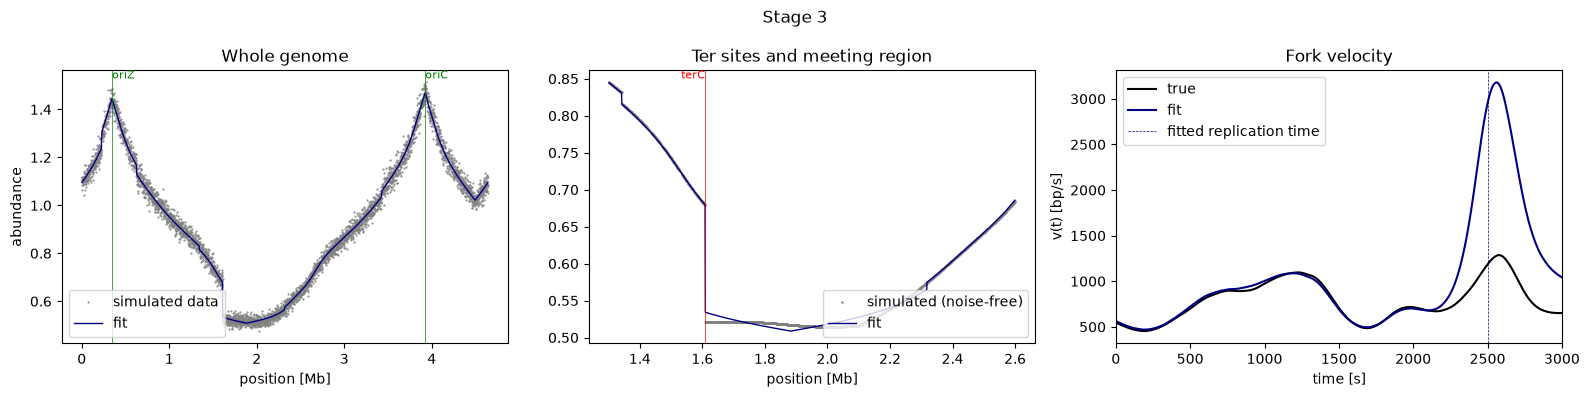

In [11]:
plot_stage(3)

## Stage 4: terC and terB, fitted v(t), other fitted delays

$p_B$ is the probability of stalling at terB *given* that the fork passed terC.

In [12]:
run_stage(4)

Stage 4: fit took 184s, origin delays oriZ 43.0s (true 45.7s), oriC 0.0s (true 0.0s)
Abundance drops at ter sites: terC 23.3%, terB 16.3%


,stage,feature,begin,end,g_true,g_fit,replicated_by,p_true,p_block
3,4,terH,599670,599693,12.4646,1.000000,clockwise (oriZ),NaN,5.924940e-17
8,4,terC,1609156,1609179,1.0000,19304.730688,clockwise (oriZ),0.596052,5.585998e-01
9,4,terB,1684225,1684248,1.0000,16412.077878,clockwise (oriZ),0.990532,9.252711e-01
10,4,terF,2317663,2317686,1.0000,223.451869,counter-clockwise (oriC),NaN,5.801965e-03
11,4,terG,2377355,2377378,1.0000,326.327683,counter-clockwise (oriC),NaN,8.433210e-03
12,4,terJ,2576244,2576267,1.0000,219.424643,counter-clockwise (oriC),NaN,5.510924e-03
25,4,rna-b3855,4040516,4040636,1.0000,5.018728,clockwise (oriC),NaN,1.178689e-03


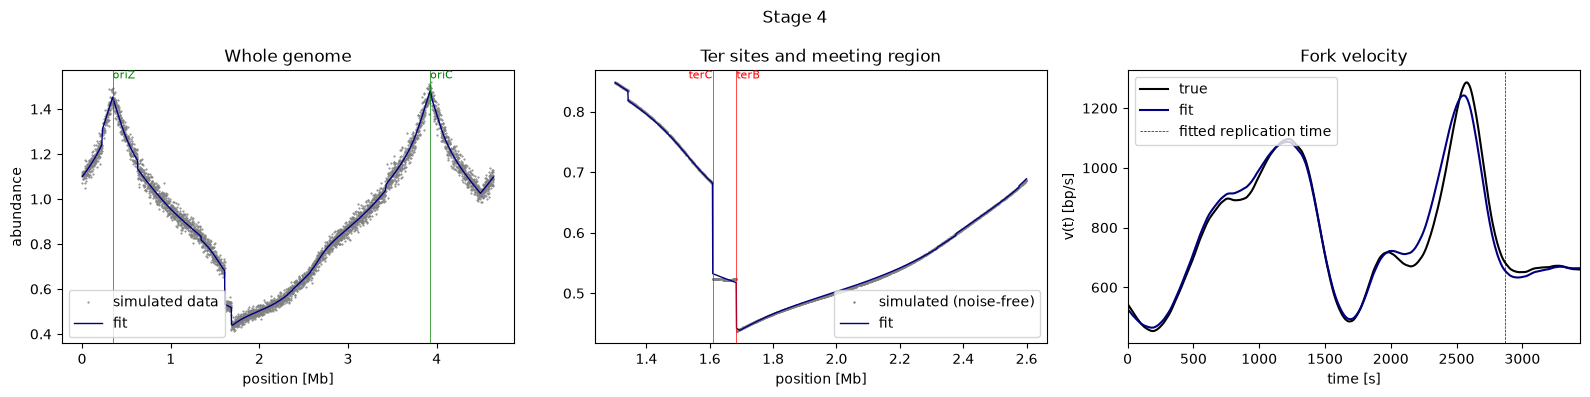

In [13]:
plot_stage(4)

## Summary

In [14]:
summary = pd.concat([RESULTS[s]["table"] for s in sorted(RESULTS)])
summary = summary.loc[~summary.p_true.isna(), ["stage", "feature", "replicated_by", "g_fit", "p_true", "p_block"]]
summary["rel_error"] = summary.p_block / summary.p_true - 1
summary

,stage,feature,replicated_by,g_fit,p_true,p_block,rel_error
0,1,terC,clockwise (oriZ),20182.095652,0.596052,0.752675,0.262768
0,2,terC,clockwise (oriZ),17341.651972,0.596052,0.760113,0.275247
8,3,terC,clockwise (oriZ),20182.095652,0.596052,0.767054,0.286891
8,4,terC,clockwise (oriZ),19304.730688,0.596052,0.558600,-0.062834
9,4,terB,clockwise (oriZ),16412.077878,0.990532,0.925271,-0.065885


## Findings

* **Full scenario (stage 4): `p_block` is accurate.** It recovers $p_C$ as 0.559 (true 0.596) and $p_B$ as 0.925
  (true 0.991), i.e. within about 7%. $v(t)$ and the oriZ delay are recovered as well. Since almost no fork from oriZ
  gets past terB ($p_B \approx 1$), the region behind terB is replicated by the fork from oriC in practically all cells.
  The deterministic model reproduces this exactly by letting the fork from oriZ exit terB just as the fork from oriC
  arrives there, so there is no mismatch between the two models in the shape of the profile.
* **terC alone (stages 1–3): `p_block` overestimates $p_C$ by 26–29%.** Here the fork from oriZ passes terC in 40% of
  the cells and continues to the meeting point with the fork from oriC. In the mixture, the meeting point stays where
  it is and the blocked fraction only lowers the profile between terC and the meeting point. A deterministic delay
  instead makes the fork from oriZ late in all cells, which moves the meeting point towards terC. The fit compensates
  with an unphysical spike of $v(t)$ at the end of replication.
* **terC hits the upper bound of $g$.** $g$ is bounded by $1 + 10 \cdot \text{delayscale} \cdot L / \text{length}$,
  which is 20182 for the 23 bp ter sites with delay scale 0.01. The fitted $g$ of terC reaches this bound in stages 1
  and 3, and also in the real fit of `T37_DNA_RCe504_R1_Exp_S2`. The delay at terC, and the $p_C = 0.596$ derived from
  it, may thus be limited by the bound in the real fit. A larger delay scale for the ter sites would avoid this.
* **Other features.** The fit puts spurious delays at terF, terG and terJ (true $g = 1$) on the side of the fork from
  oriC, and does not recover the (very small, 0.4 s) delay at terH. The rRNA genes are recovered reasonably well.
